<a href="https://colab.research.google.com/github/carlavilla/DataManagement/blob/main/Flooding_and_Housing_NJ.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [35]:
import time, os, sys, re
import zipfile, json, datetime, string
import numpy as np
from statistics import *

import matplotlib.pyplot as plt
import seaborn as sns

import pandas as pd
import pandas_datareader as pdr
from pandas_datareader import wb
from pandas.io.formats.style import Styler

import missingno as msno

from google.colab import files
from google.colab import data_table
data_table.enable_dataframe_formatter()
data_table.max_columns = 50
#!and may have to click at top right spreadsheet icon

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

#ALICE Data

Uses data from the ACS to report the number of households living in poverty as well as those in financial hardship. ALICE scores take into consideration household costs (e.g. housing, food, transportation, healthcare, technology) based on the location. Households under the ALICE threshold do not have enough income to afford their basic needs. </br>

**Variables of interest:** Per county, total number of households, households in poverty, ALICE households, ALICE income thresholds for households under 65, ALICE income thresholds for households over 65.</br>

**Timeframe available:** 2010, 2012, 2014, 2016, 2018, 2019, 2021, 2022, 2023, 2024. </br>

**Areas in dataset:** Counties in New Jersey. </br>

*Thresholds are for the average household, calculated by dividing the total number of households in each county by the population in that age group in that county.

**Source:** [United for Alice 2026 Report](https://www.unitedforalice.org/county-reports/new-jersey)

In [78]:
! wget -q -O ALICE_NJ.xlsx https://raw.githubusercontent.com/carlavilla/DataManagement/main/ALICE_NJ.xlsx
alice=pd.read_excel('ALICE_NJ.xlsx', sheet_name= "County")
alice.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 13 columns):
 #   Column                                  Non-Null Count  Dtype 
---  ------                                  --------------  ----- 
 0   State                                   210 non-null    object
 1   Year                                    210 non-null    int64 
 2   GEO.id2                                 210 non-null    int64 
 3   GEO.display_label                       210 non-null    object
 4   County                                  210 non-null    object
 5   State Abbr                              210 non-null    object
 6   Households                              210 non-null    int64 
 7   Poverty Households                      210 non-null    int64 
 8   ALICE Households                        210 non-null    int64 
 9   Above ALICE Households                  210 non-null    int64 
 10  ALICE Threshold - HH under 65           210 non-null    int64 
 11  ALICE 

In [ ]:
alice.head()

,State,Year,GEO.id2,GEO.display_label,County,State Abbr,Households,Poverty Households,ALICE Households,Above ALICE Households,ALICE Threshold - HH under 65,ALICE Threshold - HH 65 years and over,Source: American Community Survey
0,New Jersey,2010,34001,"Atlantic County, New Jersey",Atlantic,NJ\n\n,100096,12106,30689,57301,45000,40000,1-Year
1,New Jersey,2012,34001,"Atlantic County, New Jersey",Atlantic,NJ\n\n,100065,13381,32214,54470,50000,40000,1-Year
2,New Jersey,2014,34001,"Atlantic County, New Jersey",Atlantic,NJ\n\n,101937,14493,30462,56982,50000,45000,1-Year
3,New Jersey,2016,34001,"Atlantic County, New Jersey",Atlantic,NJ,96777,13436,32971,50370,60000,45000,1-Year
4,New Jersey,2018,34001,"Atlantic County, New Jersey",Atlantic,NJ\n\n,96981,12343,31914,52724,60000,50000,1-Year


In [ ]:
alice = alice.drop(columns=["State", "GEO.display_label", "GEO.id2", "State Abbr", "Source: American Community Survey "], errors='ignore')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 8 columns):
 #   Column                                  Non-Null Count  Dtype 
---  ------                                  --------------  ----- 
 0   Year                                    210 non-null    int64 
 1   County                                  210 non-null    object
 2   Households                              210 non-null    int64 
 3   Poverty Households                      210 non-null    int64 
 4   ALICE Households                        210 non-null    int64 
 5   Above ALICE Households                  210 non-null    int64 
 6   ALICE Threshold - HH under 65           210 non-null    int64 
 7   ALICE Threshold - HH 65 years and over  210 non-null    int64 
dtypes: int64(7), object(1)
memory usage: 13.3+ KB


In [ ]:
alice= alice.rename(columns={'Households': 'HH',
                             'Poverty Households': 'povertyHH',
                             'ALICE Households': 'aliceHH',
                             'Above ALICE Households': '>aliceHH',
                             'ALICE Threshold - HH under 65': 'alice$65under',
                             'ALICE Threshold - HH 65 years and over': 'alice$65over'})

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Year           210 non-null    int64 
 1   County         210 non-null    object
 2   HH             210 non-null    int64 
 3   povertyHH      210 non-null    int64 
 4   aliceHH        210 non-null    int64 
 5   >aliceHH       210 non-null    int64 
 6   alice$65under  210 non-null    int64 
 7   alice$65over   210 non-null    int64 
dtypes: int64(7), object(1)
memory usage: 13.3+ KB


<Axes: >

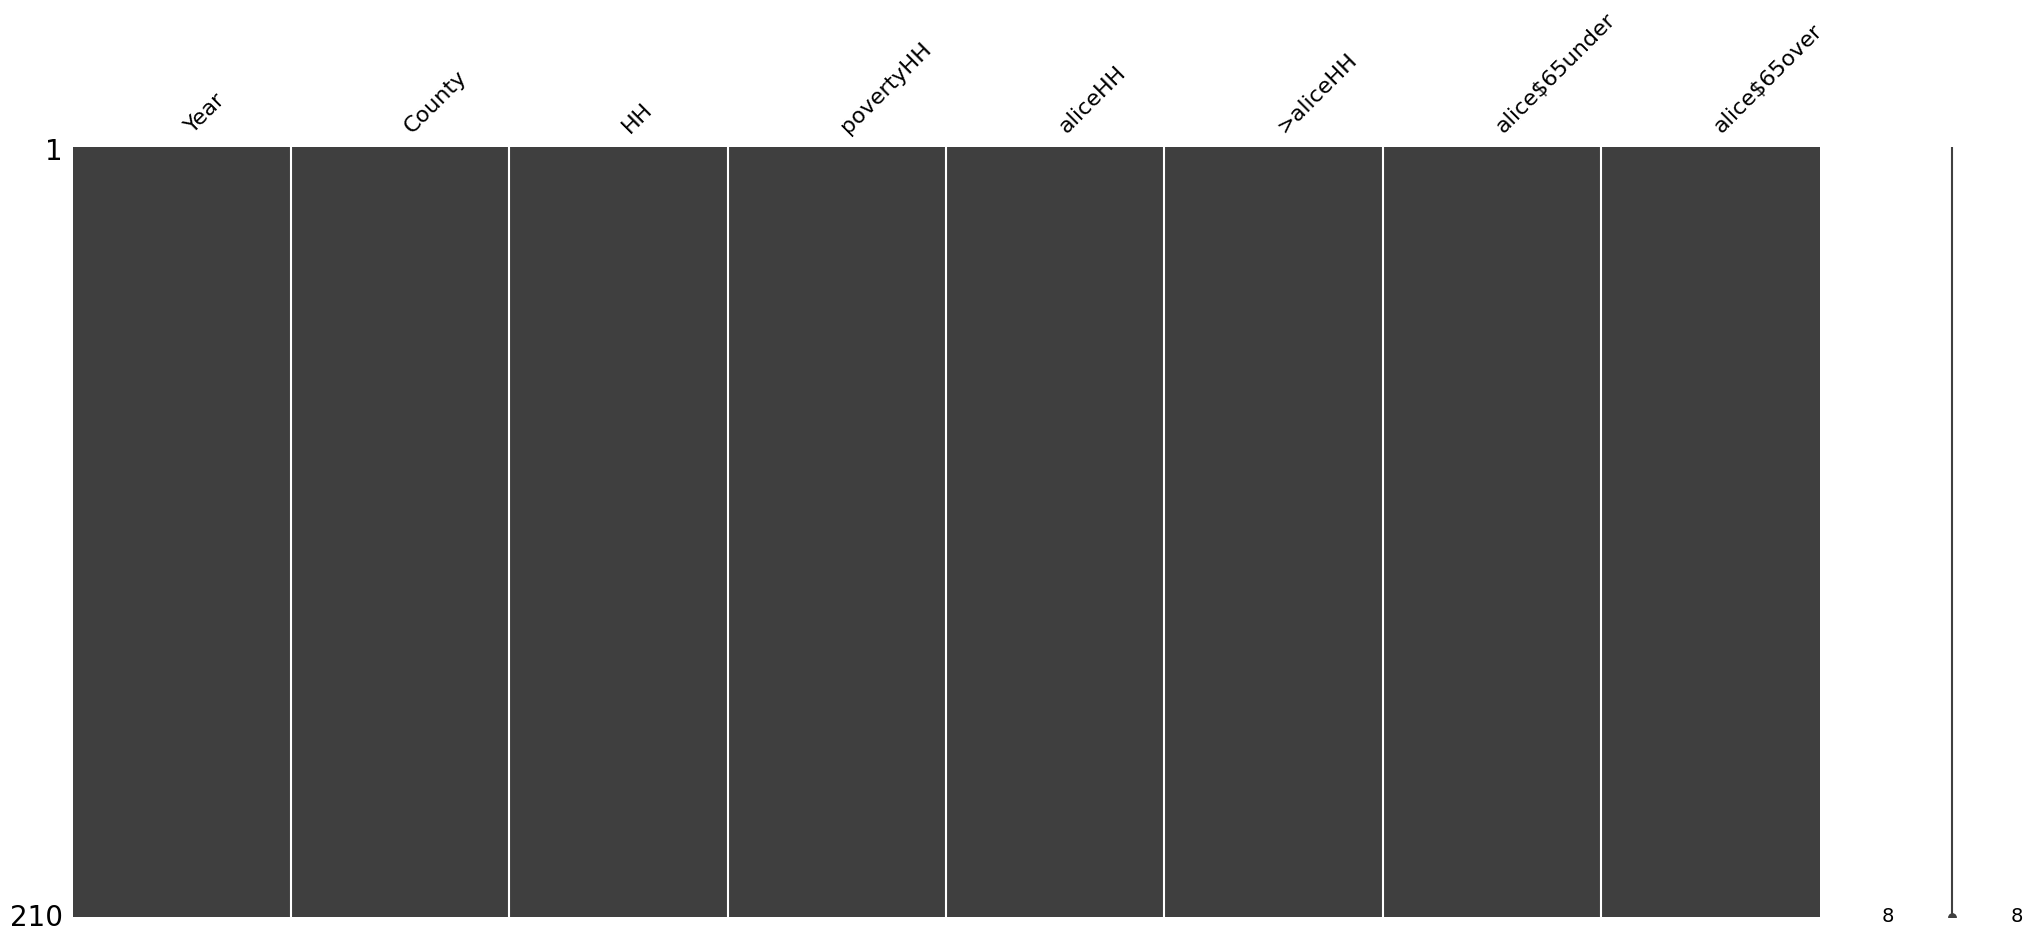

In [ ]:
msno.matrix(alice)

#ACS Data
Data on population and income for every county in New Jersey. 1-year estimates except for 2020 (obtained from 5-year estimates)

**Variables of Interest:** County, total population, total housing units, median income.

**Timeframe available:** 2010 through 2025.

**Areas in dataset:** Counties in New Jersey.

**Source:** [American Community Survey](https://www.census.gov/programs-surveys/acs/data.html)

In [36]:
! wget -q -O ACS_pop.zip https://github.com/carlavilla/DataManagement/raw/main/ACS_pop.zip
zip_ref = zipfile.ZipFile('ACS_pop.zip', 'r'); zip_ref.extractall(); zip_ref.close()
#https://raw.githubusercontent.com/carlavilla/DataManagement/main/ACS_pop.zip

In [37]:
with zipfile.ZipFile("ACS_pop.zip", 'r') as zip_ref:
    # Get a list of all file paths inside the ZIP
    pop_list = zip_ref.namelist()
    pop_list

['ACSDP1Y2025.DP05-Data.csv',
 'ACSDP1Y2025.DP05-Column-Metadata.csv',
 'ACSDP1Y2025.DP05-Table-Notes.txt',
 'ACSDP1Y2024.DP05-Data.csv',
 'ACSDP1Y2024.DP05-Column-Metadata.csv',
 'ACSDP1Y2024.DP05-Table-Notes.txt',
 'ACSDP1Y2023.DP05-Data.csv',
 'ACSDP1Y2023.DP05-Column-Metadata.csv',
 'ACSDP1Y2023.DP05-Table-Notes.txt',
 'ACSDP1Y2022.DP05-Data.csv',
 'ACSDP1Y2022.DP05-Column-Metadata.csv',
 'ACSDP1Y2022.DP05-Table-Notes.txt',
 'ACSDP1Y2021.DP05-Data.csv',
 'ACSDP1Y2021.DP05-Column-Metadata.csv',
 'ACSDP1Y2021.DP05-Table-Notes.txt',
 'ACSDP1Y2019.DP05-Data.csv',
 'ACSDP1Y2019.DP05-Column-Metadata.csv',
 'ACSDP1Y2019.DP05-Table-Notes.txt',
 'ACSDP1Y2018.DP05-Data.csv',
 'ACSDP1Y2018.DP05-Column-Metadata.csv',
 'ACSDP1Y2018.DP05-Table-Notes.txt',
 'ACSDP1Y2017.DP05-Data.csv',
 'ACSDP1Y2017.DP05-Column-Metadata.csv',
 'ACSDP1Y2017.DP05-Table-Notes.txt',
 'ACSDP1Y2016.DP05-Data.csv',
 'ACSDP1Y2016.DP05-Column-Metadata.csv',
 'ACSDP1Y2016.DP05-Table-Notes.txt',
 'ACSDP1Y2015.DP05-Data.csv'

In [38]:
acspop2010=pd.read_csv('ACSDP1Y2010.DP05-Data.csv')
acspop2010.head(3)

,GEO_ID,NAME,DP05_0001E,DP05_0001M,DP05_0001PE,DP05_0001PM,DP05_0002E,DP05_0002M,DP05_0002PE,DP05_0002PM,...,DP05_0079PM,DP05_0080E,DP05_0080M,DP05_0080PE,DP05_0080PM,DP05_0081E,DP05_0081M,DP05_0081PE,DP05_0081PM,Unnamed: 326
0,Geography,Geographic Area Name,Estimate!!SEX AND AGE!!Total population,Estimate Margin of Error!!SEX AND AGE!!Total p...,Percent!!SEX AND AGE!!Total population,Percent Margin of Error!!SEX AND AGE!!Total po...,Estimate!!SEX AND AGE!!Male,Estimate Margin of Error!!SEX AND AGE!!Male,Percent!!SEX AND AGE!!Male,Percent Margin of Error!!SEX AND AGE!!Male,...,Percent Margin of Error!!HISPANIC OR LATINO AN...,Estimate!!HISPANIC OR LATINO AND RACE!!Not His...,Estimate Margin of Error!!HISPANIC OR LATINO A...,Percent!!HISPANIC OR LATINO AND RACE!!Not Hisp...,Percent Margin of Error!!HISPANIC OR LATINO AN...,Estimate!!Total housing units,Estimate Margin of Error!!Total housing units,Percent!!Total housing units,Percent Margin of Error!!Total housing units,NaN
1,0500000US34001,"Atlantic County, New Jersey",274685,*****,274685,(X),132679,611,48.3,0.2,...,0.1,3115,1236,1.1,0.4,126723,861,(X),(X),NaN
2,0500000US34003,"Bergen County, New Jersey",906541,*****,906541,(X),436535,1088,48.2,0.1,...,0.1,10773,2346,1.2,0.3,352412,875,(X),(X),NaN


In [60]:
acspop2010= acspop2010[['NAME', 'DP05_0001E', 'DP05_0081E']]
acspop2010['Year'] = 2010
acspop10= acspop2010.drop([0])
acspop10= acspop10.rename(columns={'DP05_0081E': 'H_units'})
acspop10

,NAME,DP05_0001E,H_units,Year
1,"Atlantic County, New Jersey",274685,126723,2010
2,"Bergen County, New Jersey",906541,352412,2010
3,"Burlington County, New Jersey",449149,175728,2010
4,"Camden County, New Jersey",513607,205000,2010
5,"Cape May County, New Jersey",97253,98373,2010
6,"Cumberland County, New Jersey",157149,55856,2010
7,"Essex County, New Jersey",784228,312960,2010
8,"Gloucester County, New Jersey",288581,109949,2010
9,"Hudson County, New Jersey",635294,270578,2010
10,"Hunterdon County, New Jersey",128373,49534,2010


In [16]:
#test= acspop2010.copy()
#test= test.drop([0])
#test

,NAME,DP05_0001E,DP05_0081E,Year
1,"Atlantic County, New Jersey",274685,126723,2010
2,"Bergen County, New Jersey",906541,352412,2010
3,"Burlington County, New Jersey",449149,175728,2010
4,"Camden County, New Jersey",513607,205000,2010
5,"Cape May County, New Jersey",97253,98373,2010
6,"Cumberland County, New Jersey",157149,55856,2010
7,"Essex County, New Jersey",784228,312960,2010
8,"Gloucester County, New Jersey",288581,109949,2010
9,"Hudson County, New Jersey",635294,270578,2010
10,"Hunterdon County, New Jersey",128373,49534,2010


In [61]:
acspop2012=pd.read_csv('ACSDP1Y2012.DP05-Data.csv')
acspop2012= acspop2012[['NAME', 'DP05_0001E', 'DP05_0081E']]
acspop2012['Year'] = 2012
acspop12= acspop2012.drop([0])
acspop12= acspop12.rename(columns={'DP05_0081E': 'H_units'})
acspop12

,NAME,DP05_0001E,H_units,Year
1,"Atlantic County, New Jersey",275422,127361,2012
2,"Bergen County, New Jersey",918888,354694,2012
3,"Burlington County, New Jersey",451336,176889,2012
4,"Camden County, New Jersey",513539,205721,2012
5,"Cape May County, New Jersey",96304,98653,2012
6,"Cumberland County, New Jersey",157785,56242,2012
7,"Essex County, New Jersey",787744,313396,2012
8,"Gloucester County, New Jersey",289586,111144,2012
9,"Hudson County, New Jersey",652302,272840,2012
10,"Hunterdon County, New Jersey",127050,50053,2012


In [62]:
acspop2014=pd.read_csv('ACSDP1Y2014.DP05-Data.csv')
acspop2014= acspop2014[['NAME', 'DP05_0001E', 'DP05_0081E']]
acspop2014['Year'] = 2014
acspop14= acspop2014.drop([0])
acspop14= acspop14.rename(columns={'DP05_0081E': 'H_units'})
acspop14

,NAME,DP05_0001E,H_units,Year
1,"Atlantic County, New Jersey",275209,127386,2014
2,"Bergen County, New Jersey",933572,356367,2014
3,"Burlington County, New Jersey",449722,177671,2014
4,"Camden County, New Jersey",511038,206640,2014
5,"Cape May County, New Jersey",95344,98928,2014
6,"Cumberland County, New Jersey",157389,56363,2014
7,"Essex County, New Jersey",795723,314545,2014
8,"Gloucester County, New Jersey",290951,112272,2014
9,"Hudson County, New Jersey",669115,277172,2014
10,"Hunterdon County, New Jersey",126067,49736,2014


In [63]:
acspop2016=pd.read_csv('ACSDP1Y2016.DP05-Data.csv')
acspop2016= acspop2016[['NAME', 'DP05_0001E', 'DP05_0081E']]
acspop2016['Year'] = 2016
acspop16= acspop2016.drop([0])
acspop16= acspop16.rename(columns={'DP05_0081E': 'H_units'})
acspop16

,NAME,DP05_0001E,H_units,Year
1,"Atlantic County, New Jersey",270991,128013,2016
2,"Bergen County, New Jersey",939151,356518,2016
3,"Burlington County, New Jersey",449284,179013,2016
4,"Camden County, New Jersey",510150,205832,2016
5,"Cape May County, New Jersey",94430,99233,2016
6,"Cumberland County, New Jersey",153797,56426,2016
7,"Essex County, New Jersey",796914,315479,2016
8,"Gloucester County, New Jersey",292330,113020,2016
9,"Hudson County, New Jersey",677983,279664,2016
10,"Hunterdon County, New Jersey",124676,50132,2016


In [59]:
acspop2018=pd.read_csv('ACSDP1Y2018.DP05-Data.csv')
acspop2018= acspop2018[['NAME', 'DP05_0001E', 'DP05_0086E']]
acspop2018['Year'] = 2018
acspop18= acspop2018.drop([0])
acspop18= acspop18.rename(columns={'DP05_0086E': 'H_units'})
acspop18

,NAME,DP05_0001E,H_units,Year
1,"Atlantic County, New Jersey",265429,128408,2018
2,"Bergen County, New Jersey",936692,359241,2018
3,"Burlington County, New Jersey",445384,179900,2018
4,"Camden County, New Jersey",507078,206109,2018
5,"Cape May County, New Jersey",92560,99427,2018
6,"Cumberland County, New Jersey",150972,56497,2018
7,"Essex County, New Jersey",799767,318814,2018
8,"Gloucester County, New Jersey",291408,113907,2018
9,"Hudson County, New Jersey",676061,284124,2018
10,"Hunterdon County, New Jersey",124714,50454,2018


In [64]:
acspop2019=pd.read_csv('ACSDP1Y2019.DP05-Data.csv')
acspop2019= acspop2019[['NAME', 'DP05_0001E', 'DP05_0086E']]
acspop2019['Year'] = 2019
acspop19= acspop2019.drop([0])
acspop19= acspop19.rename(columns={'DP05_0086E': 'H_units'})
acspop19

,NAME,DP05_0001E,H_units,Year
1,"Atlantic County, New Jersey",263670,128951,2019
2,"Bergen County, New Jersey",932202,360822,2019
3,"Burlington County, New Jersey",445349,180448,2019
4,"Camden County, New Jersey",506471,206368,2019
5,"Cape May County, New Jersey",92039,99630,2019
6,"Cumberland County, New Jersey",149527,56471,2019
7,"Essex County, New Jersey",798975,319689,2019
8,"Gloucester County, New Jersey",291636,114452,2019
9,"Hudson County, New Jersey",672391,286907,2019
10,"Hunterdon County, New Jersey",124371,50554,2019


In [65]:
acspop2021=pd.read_csv('ACSDP1Y2021.DP05-Data.csv')
acspop2021= acspop2021[['NAME', 'DP05_0001E', 'DP05_0086E']]
acspop2021['Year'] = 2021
acspop21= acspop2021.drop([0])
acspop21= acspop21.rename(columns={'DP05_0086E': 'H_units'})
acspop21

,NAME,DP05_0001E,H_units,Year
1,"Atlantic County, New Jersey",274966,132214,2021
2,"Bergen County, New Jersey",953819,369201,2021
3,"Burlington County, New Jersey",464269,186150,2021
4,"Camden County, New Jersey",523771,213475,2021
5,"Cape May County, New Jersey",95661,99233,2021
6,"Cumberland County, New Jersey",153627,57204,2021
7,"Essex County, New Jersey",854917,336277,2021
8,"Gloucester County, New Jersey",304477,117734,2021
9,"Hudson County, New Jersey",702463,317049,2021
10,"Hunterdon County, New Jersey",129924,51904,2021


In [66]:
acspop2022=pd.read_csv('ACSDP1Y2022.DP05-Data.csv')
acspop2022= acspop2022[['NAME', 'DP05_0001E', 'DP05_0088E']]
acspop2022['Year'] = 2022
acspop22= acspop2022.drop([0])
acspop22= acspop22.rename(columns={'DP05_0088E': 'H_units'})
acspop22

,NAME,DP05_0001E,H_units,Year
1,"Atlantic County, New Jersey",275638,132154,2022
2,"Bergen County, New Jersey",952997,369379,2022
3,"Burlington County, New Jersey",466103,186200,2022
4,"Camden County, New Jersey",524907,213805,2022
5,"Cape May County, New Jersey",95634,99408,2022
6,"Cumberland County, New Jersey",151356,57254,2022
7,"Essex County, New Jersey",849477,336538,2022
8,"Gloucester County, New Jersey",306601,117807,2022
9,"Hudson County, New Jersey",703366,319614,2022
10,"Hunterdon County, New Jersey",129777,51952,2022


In [67]:
acspop2023=pd.read_csv('ACSDP1Y2023.DP05-Data.csv')
acspop2023= acspop2023[['NAME', 'DP05_0001E', 'DP05_0091E']]
acspop2023['Year'] = 2023
acspop23= acspop2023.drop([0])
acspop23= acspop23.rename(columns={'DP05_0091E': 'H_units'})
acspop23

,NAME,DP05_0001E,H_units,Year
1,"Atlantic County, New Jersey",275213,132179,2023
2,"Bergen County, New Jersey",957736,370464,2023
3,"Burlington County, New Jersey",469167,186753,2023
4,"Camden County, New Jersey",527196,213947,2023
5,"Cape May County, New Jersey",94610,99491,2023
6,"Cumberland County, New Jersey",152326,57336,2023
7,"Essex County, New Jersey",851117,337500,2023
8,"Gloucester County, New Jersey",308423,118177,2023
9,"Hudson County, New Jersey",705472,325334,2023
10,"Hunterdon County, New Jersey",130183,52256,2023


In [68]:
acspop2024=pd.read_csv('ACSDP1Y2024.DP05-Data.csv')
acspop2024= acspop2024[['NAME', 'DP05_0001E', 'DP05_0105E']]
acspop2024['Year'] = 2024
acspop24= acspop2024.drop([0])
acspop24= acspop24.rename(columns={'DP05_0105E': 'H_units'})
acspop24

,NAME,DP05_0001E,H_units,Year
1,"Atlantic County, New Jersey",279114,132307,2024
2,"Bergen County, New Jersey",978641,371207,2024
3,"Burlington County, New Jersey",475515,187321,2024
4,"Camden County, New Jersey",533988,214642,2024
5,"Cape May County, New Jersey",93875,97798,2024
6,"Cumberland County, New Jersey",155678,57446,2024
7,"Essex County, New Jersey",881527,339451,2024
8,"Gloucester County, New Jersey",311783,118541,2024
9,"Hudson County, New Jersey",736185,326976,2024
10,"Hunterdon County, New Jersey",131708,52633,2024


In [72]:
acspop= pd.concat([acspop10, acspop12, acspop14, acspop16, acspop18, acspop19, acspop21, acspop22, acspop23, acspop24])
acspop.rename(columns={'NAME': 'County',
                       'DP05_0001E': "Totalpop"},
              inplace=True)
acspop= acspop.reset_index(drop=True)
acspop.head(3)

,County,Totalpop,H_units,Year
0,"Atlantic County, New Jersey",274685,126723,2010
1,"Bergen County, New Jersey",906541,352412,2010
2,"Burlington County, New Jersey",449149,175728,2010


In [77]:
acspop['County'] = acspop['County'].str.replace(' County, New Jersey', '')
acspop.head(3)

,County,Totalpop,H_units,Year
0,Atlantic,274685,126723,2010
1,Bergen,906541,352412,2010
2,Burlington,449149,175728,2010


<Axes: >

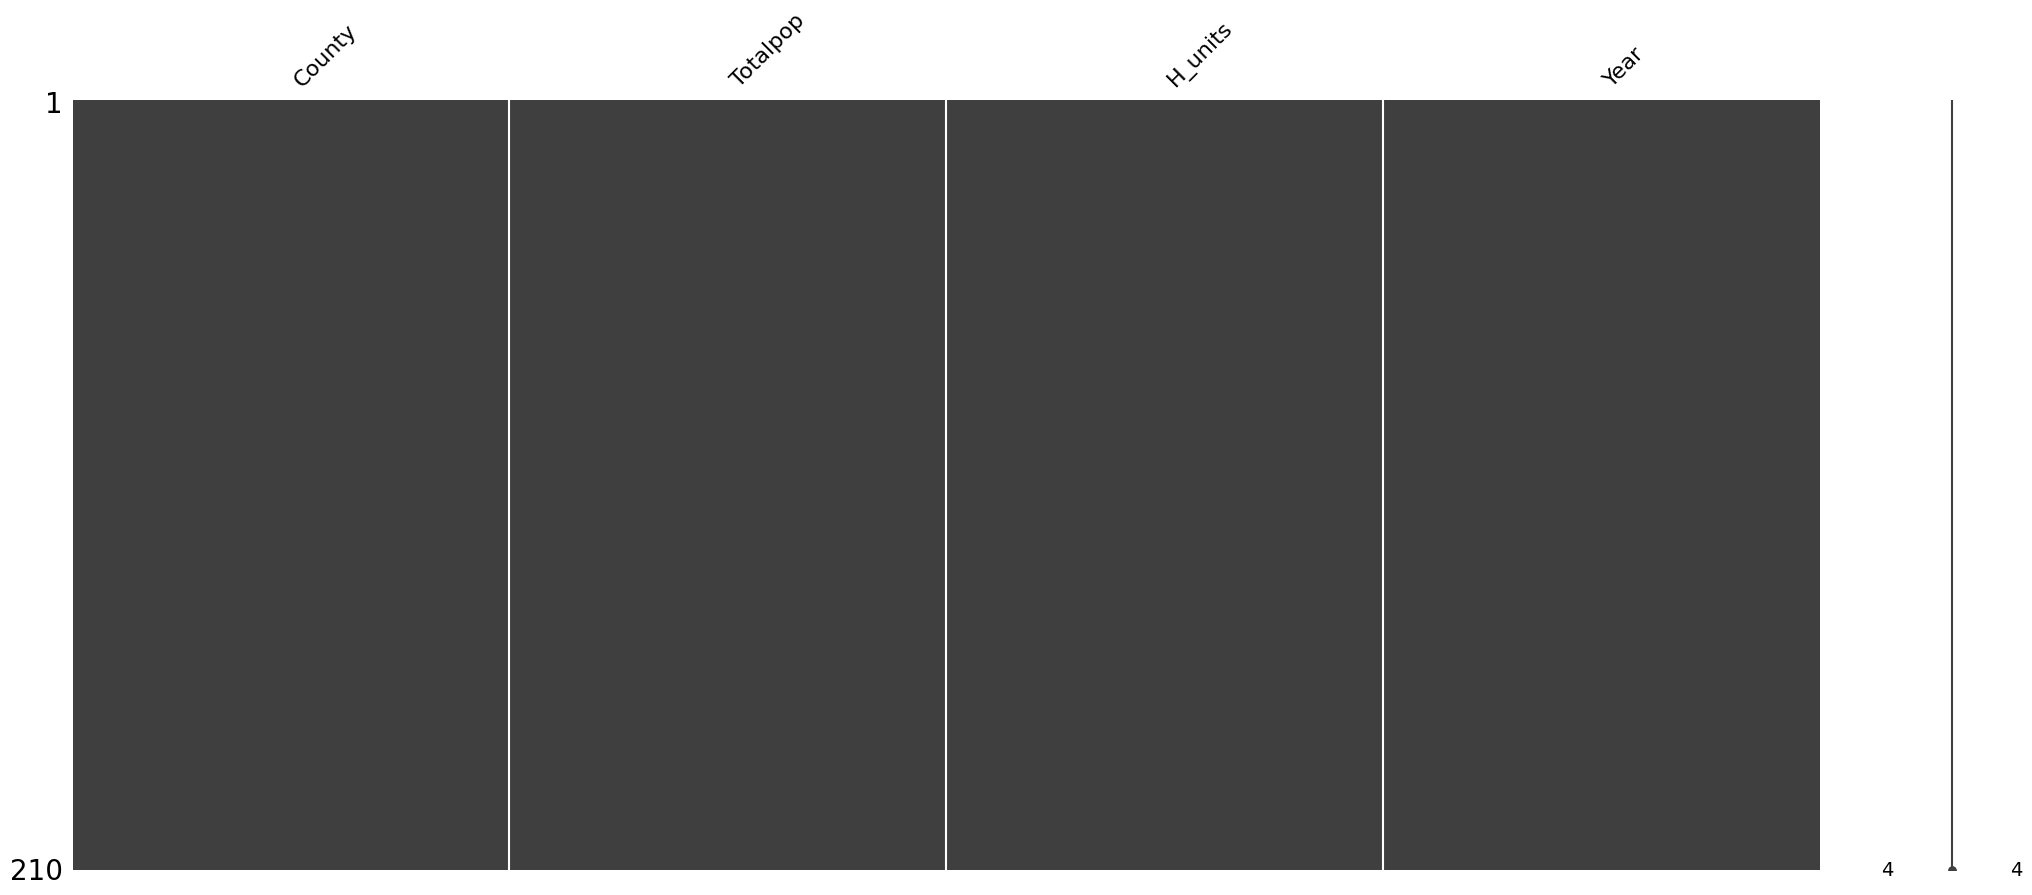

In [79]:
msno.matrix(acspop)

In [80]:
! wget -q -O ACS_income.zip https://github.com/carlavilla/DataManagement/raw/main/ACS_income.zip
zip_ref = zipfile.ZipFile('ACS_income.zip', 'r'); zip_ref.extractall(); zip_ref.close()

In [81]:
with zipfile.ZipFile("ACS_income.zip", 'r') as zip_ref:
    income_list = zip_ref.namelist()
    income_list

['ACSST1Y2025.S1901-Data.csv',
 'ACSST1Y2025.S1901-Column-Metadata.csv',
 'ACSST1Y2025.S1901-Table-Notes.txt',
 'ACSST1Y2024.S1901-Data.csv',
 'ACSST1Y2024.S1901-Column-Metadata.csv',
 'ACSST1Y2024.S1901-Table-Notes.txt',
 'ACSST1Y2023.S1901-Data.csv',
 'ACSST1Y2023.S1901-Column-Metadata.csv',
 'ACSST1Y2023.S1901-Table-Notes.txt',
 'ACSST1Y2022.S1901-Data.csv',
 'ACSST1Y2022.S1901-Column-Metadata.csv',
 'ACSST1Y2022.S1901-Table-Notes.txt',
 'ACSST1Y2021.S1901-Data.csv',
 'ACSST1Y2021.S1901-Column-Metadata.csv',
 'ACSST1Y2021.S1901-Table-Notes.txt',
 'ACSST1Y2019.S1901-Data.csv',
 'ACSST1Y2019.S1901-Column-Metadata.csv',
 'ACSST1Y2019.S1901-Table-Notes.txt',
 'ACSST1Y2018.S1901-Data.csv',
 'ACSST1Y2018.S1901-Column-Metadata.csv',
 'ACSST1Y2018.S1901-Table-Notes.txt',
 'ACSST1Y2017.S1901-Data.csv',
 'ACSST1Y2017.S1901-Column-Metadata.csv',
 'ACSST1Y2017.S1901-Table-Notes.txt',
 'ACSST1Y2016.S1901-Data.csv',
 'ACSST1Y2016.S1901-Column-Metadata.csv',
 'ACSST1Y2016.S1901-Table-Notes.txt',
 

In [93]:
acsinc2010=pd.read_csv('ACSST1Y2010.S1901-Data.csv')
acsinc2010= acsinc2010[['NAME', 'S1901_C01_012E']]
acsinc2010['Year'] = 2010
acsinc10= acsinc2010.drop([0])
acsinc10= acsinc10.rename(columns={'S1901_C01_012E': 'Median_income'})

acsinc2012=pd.read_csv('ACSST1Y2012.S1901-Data.csv')
acsinc2012= acsinc2012[['NAME', 'S1901_C01_012E']]
acsinc2012['Year'] = 2012
acsinc12= acsinc2012.drop([0])
acsinc12= acsinc12.rename(columns={'S1901_C01_012E': 'Median_income'})

acsinc2014=pd.read_csv('ACSST1Y2014.S1901-Data.csv')
acsinc2014= acsinc2014[['NAME', 'S1901_C01_012E']]
acsinc2014['Year'] = 2014
acsinc14= acsinc2014.drop([0])
acsinc14= acsinc14.rename(columns={'S1901_C01_012E': 'Median_income'})

acsinc2016=pd.read_csv('ACSST1Y2016.S1901-Data.csv')
ascinc2016= acsinc2016[['NAME', 'S1901_C01_012E']]
acsinc2016['Year'] = 2016
acsinc16= acsinc2016.drop([0])
acsinc16= acsinc16.rename(columns={'S1901_C01_012E': 'Median_income'})

acsinc2018=pd.read_csv('ACSST1Y2018.S1901-Data.csv')
ascinc2018= acsinc2018[['NAME', 'S1901_C01_012E']]
acsinc2018['Year'] = 2018
acsinc18= acsinc2018.drop([0])
acsinc18= acsinc18.rename(columns={'S1901_C01_012E': 'Median_income'})

acsinc2019=pd.read_csv('ACSST1Y2019.S1901-Data.csv')
ascinc2019= acsinc2019[['NAME', 'S1901_C01_012E']]
acsinc2019['Year'] = 2019
acsinc19= acsinc2019.drop([0])
acsinc19= acsinc19.rename(columns={'S1901_C01_012E': 'Median_income'})

acsinc2021=pd.read_csv('ACSST1Y2021.S1901-Data.csv')
ascinc2021= acsinc2021[['NAME', 'S1901_C01_012E']]
acsinc2021['Year'] = 2021
acsinc21= acsinc2021.drop([0])
acsinc21= acsinc21.rename(columns={'S1901_C01_012E': 'Median_income'})

acsinc2022=pd.read_csv('ACSST1Y2022.S1901-Data.csv')
ascinc2022= acsinc2022[['NAME', 'S1901_C01_012E']]
acsinc2022['Year'] = 2022
acsinc22= acsinc2022.drop([0])
acsinc22= acsinc22.rename(columns={'S1901_C01_012E': 'Median_income'})

acsinc2023=pd.read_csv('ACSST1Y2023.S1901-Data.csv')
ascinc2023= acsinc2023[['NAME', 'S1901_C01_012E']]
acsinc2023['Year'] = 2023
acsinc23= acsinc2023.drop([0])
acsinc23= acsinc23.rename(columns={'S1901_C01_012E': 'Median_income'})

acsinc2024=pd.read_csv('ACSST1Y2024.S1901-Data.csv')
ascinc2024= acsinc2024[['NAME', 'S1901_C01_012E']]
acsinc2024['Year'] = 2024
acsinc24= acsinc2024.drop([0])
acsinc24= acsinc24.rename(columns={'S1901_C01_012E': 'Median_income'})

In [94]:
acsinc= pd.concat([acsinc10, acsinc12, acsinc14, acsinc16, acsinc18, acsinc19, acsinc21, acsinc22, acsinc23, acsinc24])
acsinc.rename(columns={'NAME': 'County'},
              inplace=True)
acsinc['County'] = acsinc['County'].str.replace(' County, New Jersey', '')
acsinc= acsinc.reset_index(drop=True)
acsinc.head(3)

,County,Median_income,Year,GEO_ID,S1901_C01_001E,S1901_C01_001M,S1901_C02_001E,S1901_C02_001M,S1901_C03_001E,S1901_C03_001M,...,S1901_C04_015M,S1901_C01_016E,S1901_C01_016M,S1901_C02_016E,S1901_C02_016M,S1901_C03_016E,S1901_C03_016M,S1901_C04_016E,S1901_C04_016M,Unnamed: 130
0,Atlantic,52571,2010,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Bergen,77389,2010,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Burlington,74329,2010,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
